# Chapitre 8 - Cours 2 : Augmentation et synthèse de données

Annoter coûte cher, et certaines données sont rares, dangereuses ou privées. Depuis
longtemps, l'industrie rêve de **produire des données par programme**. Ce notebook suit
la section *Data Augmentation and Synthesis* du livre :

1. augmentation ou synthèse, et **pourquoi** synthétiser (section *Why Data Synthesis*) ;
2. les techniques **à base de règles** : gabarits (section *Rule-based data synthesis*) ;
3. les **transformations et perturbations** : substitution, contrefactuels de genre,
   fautes de frappe, avec une expérience de robustesse ;
4. la **simulation** (section *Simulation*) ;
5. la **synthèse d'instructions par IA** avec Qwen2.5 (sections *AI-Powered Data
   Synthesis* et *Instruction data synthesis*) ;
6. la **vérification** des données synthétiques (section *Data verification*) ;
7. les **limites**, dont l'**effondrement de modèle** illustré par simulation (section
   *Limitations to AI-generated data*) ;
8. la **distillation** de modèles (section *Model Distillation*).

Modèles utilisés : Qwen2.5-1.5B-Instruct comme **générateur** (la qualité du français
l'exige : le 0,5B produit trop souvent des phrases incohérentes pour servir de source) et
Qwen2.5-0.5B-Instruct comme **solveur** dont on vérifie les réponses. Les deux ne sont
jamais chargés en même temps, pour ménager la mémoire du GPU.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch08_donnees as d8
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
GEN = llm.MEDIUM   # générateur de données synthétiques
SOLV = llm.SMALL   # petit modèle dont on vérifie les sorties


def titre(ax, texte, sous_titre):
    """Titre d'axe suivi d'un sous-titre gris."""
    ax.set_title(texte, pad=18)
    subtitle(ax, sous_titre)

def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (la police du socle n'a pas le signe moins
    typographique utilisé par les exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())


def court(t, n=110):
    """Tronque un texte pour l'affichage."""
    t = " ".join(t.split())
    return t if len(t) <= n else t[:n - 3] + "..."

## 1. Augmenter ou synthétiser ? (section *Why Data Synthesis*)

Le livre distingue deux processus :

- l'**augmentation** crée de nouvelles données **à partir de données réelles** (retourner
  la photo d'un chat donne une autre photo du même chat) ;
- la **synthèse** génère des données qui **imitent** les propriétés des données réelles
  (simuler les mouvements de souris d'un robot sur une page web).

Le but commun étant d'automatiser la création de données, le livre emploie souvent
« synthèse » pour les deux. Il recense cinq motivations : améliorer le trio
**quantité, couverture, qualité**, protéger la **vie privée**, et **distiller** des
modèles.

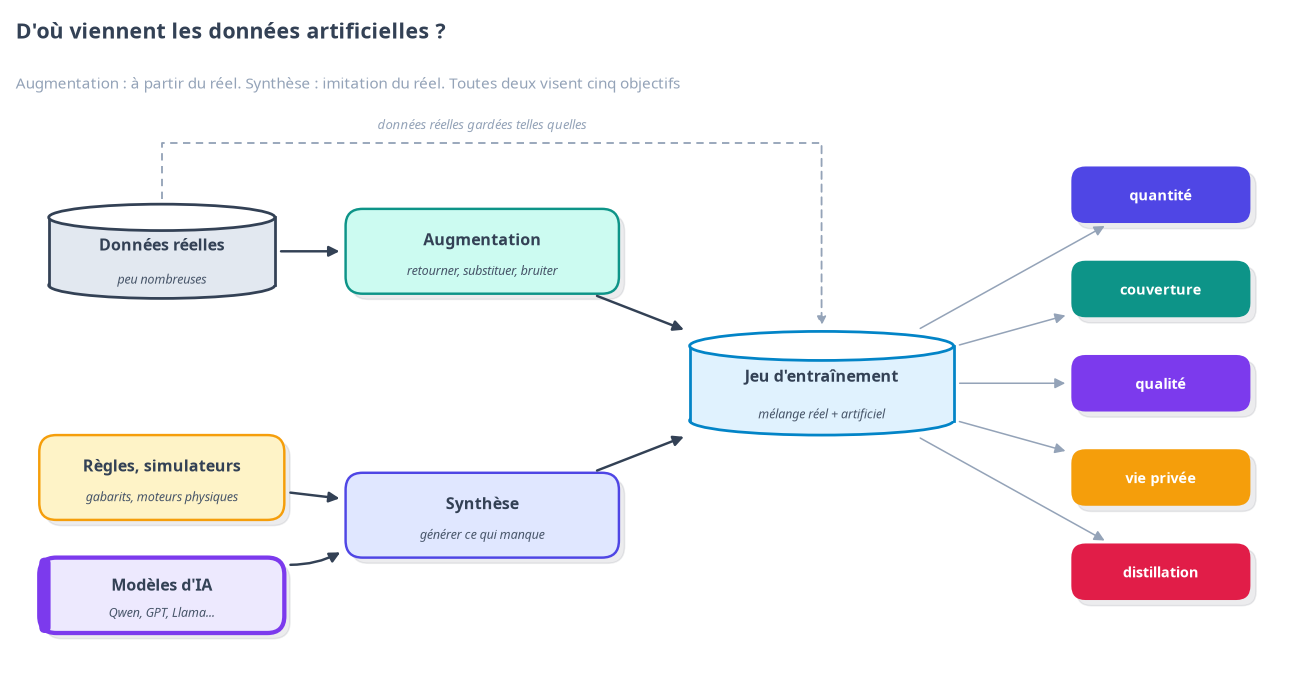

In [2]:
d = Diagram(13.5, 6.0, title="D'où viennent les données artificielles ?",
            subtitle="Augmentation : à partir du réel. Synthèse : imitation du réel. Toutes deux visent cinq objectifs")
d.box("reel", 1.6, 4.4, "Données réelles", sub="peu nombreuses", color=SLATE, kind="db", w=2.4, h=1.0)
d.box("aug", 5.0, 4.4, "Augmentation", sub="retourner, substituer, bruiter", color=TEAL, w=2.9)
d.box("regles", 1.6, 2.0, "Règles, simulateurs", sub="gabarits, moteurs physiques", color=AMBER, w=2.6)
d.box("ia", 1.6, 0.75, "Modèles d'IA", sub="Qwen, GPT, Llama...", color=VIOLET, kind="model", w=2.6, h=0.8)
d.box("syn", 5.0, 1.6, "Synthèse", sub="générer ce qui manque", color=INDIGO, w=2.9)
d.box("jeu", 8.6, 3.0, "Jeu d'entraînement", sub="mélange réel + artificiel", color=SKY, kind="db", w=2.8, h=1.1)
d.arrow("reel", "aug")
d.arrow("regles", "syn")
d.arrow("ia", "syn", rad=0.15)
d.arrow("aug", "jeu")
d.arrow("syn", "jeu")
d.line([(1.6, 4.95), (1.6, 5.55), (8.6, 5.55), (8.6, 3.58)], color=GRAY, style="dashed")
d.note(5.0, 5.75, "données réelles gardées telles quelles", color=GRAY, fontsize=8.5)
for i, (t, c) in enumerate([("quantité", INDIGO), ("couverture", TEAL), ("qualité", VIOLET),
                            ("vie privée", AMBER), ("distillation", ROSE)]):
    y = 5.0 - i * 1.0
    d.box(f"o{i}", 12.2, y, t, color=c, kind="tag", w=1.9, h=0.6, fontsize=9.5)
    d.arrow("jeu", f"o{i}", color=GRAY, lw=1.0)
d.show()

Quelques exemples du livre pour chaque objectif :

| Objectif | Idée | Exemple |
|---|---|---|
| Quantité | produire à l'échelle là où le réel est rare | accidents pour la conduite autonome |
| Couverture | cibler des comportements ou classes rares | résumés volontairement incohérents pour entraîner un détecteur (TrueTeacher) |
| Qualité | dépasser les limites humaines | données d'usage d'outils, problèmes de maths difficiles, préférences plus cohérentes |
| Vie privée | remplacer des données sensibles | dossiers médicaux ou sinistres d'assurance synthétiques |
| Distillation | imiter un modèle plus gros | entraîner un petit modèle sur les sorties d'un grand |

> **À retenir.** L'augmentation transforme des données réelles, la synthèse imite le
> réel. On y recourt pour la quantité, la couverture, la qualité, la vie privée et la
> distillation, mais les données artificielles **complètent** les données humaines plus
> qu'elles ne les remplacent.

## 2. Règles et gabarits (section *Rule-based data synthesis*)

La méthode la plus simple : un **gabarit** dont on remplit les champs par tirage
aléatoire (comme le fait la bibliothèque Faker). C'est la **génération procédurale** des
jeux vidéo, appliquée aux données. Le livre prend l'exemple de transactions bancaires :
trop sensibles pour être partagées, elles sont d'abord synthétisées pour prouver la
faisabilité d'un détecteur de fraude. Faisons-le, en injectant volontairement 3 % de
fraudes (une classe rare que l'on veut **couvrir**).

In [3]:
marchands = {"alimentation": ["Carrefour Market", "Biocoop", "Boulangerie Paul"],
             "transport": ["SNCF Connect", "Uber", "TotalEnergies"],
             "loisirs": ["Fnac", "Cinéma Pathé", "Decathlon"],
             "en ligne": ["Amazon", "Vinted", "Steam"]}
villes = ["Lyon, France", "Paris, France", "Lille, France", "Nantes, France"]


def transaction(i, rng, fraude=False):
    cat = list(marchands)[rng.integers(4)]
    montant = rng.lognormal(3.2, 0.8) if not fraude else rng.uniform(900, 4000)
    heure = int(rng.integers(7, 23)) if not fraude else int(rng.integers(1, 5))
    return {"id": f"TX{i:05d}", "date": f"2026-{rng.integers(1, 13):02d}-{rng.integers(1, 29):02d}",
            "heure": f"{heure:02d}:{rng.integers(60):02d}", "montant (euros)": round(float(montant), 2),
            "marchand": marchands[cat][rng.integers(3)], "catégorie": cat,
            "lieu": villes[rng.integers(4)] if not fraude else "Lagos, Nigeria",
            "statut": rng.choice(["validée", "validée", "validée", "en attente", "refusée"]),
            "fraude": int(fraude)}


tx = pd.DataFrame([transaction(i, rng, fraude=rng.random() < 0.03) for i in range(2000)])
tx.head(6)

,id,date,heure,montant (euros),marchand,catégorie,lieu,statut,fraude
0,TX00000,2026-01-01,11:10,40.95,Decathlon,loisirs,"Lille, France",refusée,0
1,TX00001,2026-07-27,18:16,13.97,Steam,en ligne,"Lille, France",validée,0
2,TX00002,2026-11-05,07:05,9.05,Decathlon,loisirs,"Lyon, France",validée,0
3,TX00003,2026-01-04,13:00,22.14,TotalEnergies,transport,"Lille, France",en attente,0
4,TX00004,2026-10-28,13:22,13.53,Steam,en ligne,"Nantes, France",en attente,0
5,TX00005,2026-07-21,13:50,21.60,Cinéma Pathé,loisirs,"Paris, France",validée,0


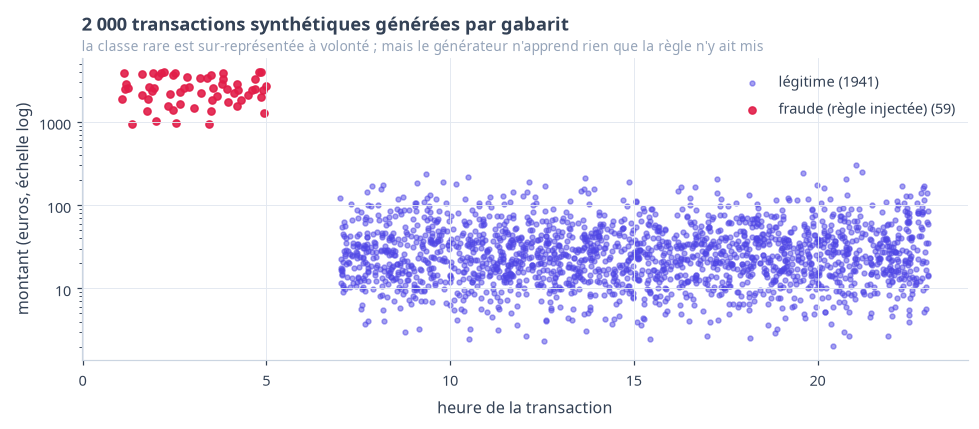

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for f, c, lab in [(0, INDIGO, "légitime"), (1, ROSE, "fraude (règle injectée)")]:
    sub = tx[tx.fraude == f]
    ax.scatter(sub["heure"].str[:2].astype(int) + rng.random(len(sub)), sub["montant (euros)"],
               s=10 if f == 0 else 22, alpha=0.5 if f == 0 else 0.9, color=c, label=f"{lab} ({len(sub)})")
ax.set_yscale("log")
log_lisible(ax)
ax.set_xlabel("heure de la transaction")
ax.set_ylabel("montant (euros, échelle log)")
titre(ax, "2 000 transactions synthétiques générées par gabarit",
      "la classe rare est sur-représentée à volonté ; mais le générateur n'apprend rien que la règle n'y ait mis")
ax.legend(loc="upper right")
finish(fig)
plt.show()

Le revers de la médaille est visible : la fraude est **parfaitement séparable** parce que
nous l'avons définie par une règle simple. Un détecteur entraîné sur ces données
apprendra notre règle, pas la fraude réelle. Les gabarits servent donc à **démarrer**
(prouver la faisabilité, tester un pipeline), avant l'accès aux vraies données.

Les gabarits brillent quand la donnée suit une **grammaire** : documents structurés
(factures, CV), expressions régulières, **équations et problèmes de maths**. Le livre
cite AlphaGeometry, entraîné sur 100 millions d'exemples synthétiques. Nous générons
ainsi des problèmes arithmétiques dont **la réponse est connue par construction**, ce
qui servira à la vérification (section 6).

In [5]:
problemes = d8.make_word_problems(6, seed=1)
pd.DataFrame(problemes)[["question", "answer"]]

,question,answer
0,"Un train transporte 57 passagers. À la gare, 9 descendent et 9 montent. Combien de passagers y a-t-il dans...",57
1,"Une boulangerie a 57 croissants. Elle en vend 4, puis en cuit 10 de plus. Combien de croissants a-t-elle m...",63
2,Léa possède 29 billes. Elle en donne 6 à son frère et en gagne 10 à la récréation. Combien de billes a-t-e...,33
3,Léa possède 32 billes. Elle en donne 12 à son frère et en gagne 4 à la récréation. Combien de billes a-t-e...,24
4,Un magasin reçoit 2 cartons de 9 bouteilles et en avait déjà 11. Combien de bouteilles a-t-il au total ?,29
5,Une salle compte 10 rangées de 12 chaises. On retire 38 chaises abîmées. Combien reste-t-il de chaises ?,82


**Combien de gabarits ?** Le livre met en garde : produire trop d'exemples par gabarit
appauvrit la diversité. Mesurons-le avec distinct-2 (cours 1) : on génère 200
instructions en répartissant l'effort sur 1, 2, 5 ou 10 gabarits.

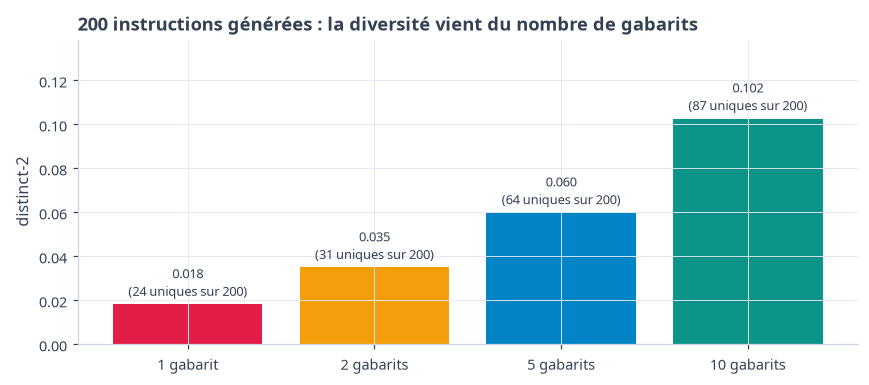

In [6]:
gabarits = ["Donne-moi une recette de {x} pour {n} personnes.", "Comment conserver des {x} plus longtemps ?",
            "Quel vin servir avec des {x} ?", "Explique à un enfant d'où viennent les {x}.",
            "Combien de calories contiennent {n} portions de {x} ?", "Propose une variante végétarienne des {x}.",
            "Quelles erreurs éviter quand on prépare des {x} ?", "Écris un poème court sur les {x}.",
            "Résume l'histoire des {x} en trois phrases.", "Compare les {x} maison et industriels."]
champs = {"x": ["crêpes", "lasagnes", "quiches", "soupes", "tartes", "gratins", "risottos", "gaufres"],
          "n": ["deux", "quatre", "six"]}
res = []
for k in [1, 2, 5, 10]:
    txt = [d8.fill_template(gabarits[i % k], champs, rng) for i in range(200)]
    res.append((k, d8.distinct_n(txt, 2), len(set(txt))))
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar([f"{k} gabarit{'s' if k > 1 else ''}" for k, *_ in res], [r[1] for r in res],
              color=[ROSE, AMBER, SKY, TEAL])
ax.bar_label(bars, labels=[f"{r[1]:.3f}\n({r[2]} uniques sur 200)" for r in res], fontsize=8.5, padding=3)
ax.set_ylabel("distinct-2")
ax.set_ylim(0, max(r[1] for r in res) * 1.35)
ax.set_title("200 instructions générées : la diversité vient du nombre de gabarits")
finish(fig)
plt.show()

Avec un seul gabarit, il n'existe que $8 \times 3 = 24$ instructions possibles : 200
tirages produisent forcément des doublons. La diversité d'un jeu à gabarits est
**bornée par la combinatoire** des gabarits et des champs.

> **À retenir.** Les gabarits produisent des données structurées et **vérifiables** à
> très bas coût, idéales pour démarrer ou pour des domaines à grammaire (maths, code,
> documents). Mais ils ne contiennent que ce que la règle y a mis, et leur diversité est
> bornée par la combinatoire : multipliez les gabarits plutôt que les tirages.

## 3. Transformations et perturbations (section *Rule-based data synthesis*)

### Substitution et contrefactuels

On peut créer un exemple en remplaçant un mot par un synonyme (« une infirmière
formidable » donne « une infirmière remarquable »), trouvé dans un dictionnaire ou par
proximité d'embeddings. Appliquée aux mots genrés, la substitution produit des
**contrefactuels** qui atténuent un biais : si « nurse » n'apparaît qu'avec « she », on
ajoute les versions avec « he ». Notre fonction `gender_swap` le fait en anglais (le
tableau 8-2 du livre en donne des exemples).

In [7]:
phrases = ["She is a wonderful nurse and her patients love her.",
           "Mr. Lee told his son that the engineer had fixed the bridge.",
           "My mom cooked dinner while my dad read a book.",
           "The waitress thanked the gentleman for his tip."]
pd.DataFrame({"original": phrases, "contrefactuel": [d8.gender_swap(p) for p in phrases]})

,original,contrefactuel
0,She is a wonderful nurse and her patients love her.,He is a wonderful nurse and his patients love his.
1,Mr. Lee told his son that the engineer had fixed the bridge.,Ms. Lee told her daughter that the engineer had fixed the bridge.
2,My mom cooked dinner while my dad read a book.,My dad cooked dinner while my mom read a book.
3,The waitress thanked the gentleman for his tip.,The waiter thanked the lady for her tip.


Regardez la première ligne : « love her » devient « love his », une faute. En anglais,
« her » correspond tantôt à « his » (possessif), tantôt à « him » (complément) : un
dictionnaire ne peut pas trancher sans analyse grammaticale. En français, c'est pire
(accords : « une infirmière dévouée » doit devenir « un infirmier dévoué »).
L'exercice 8.6 explore ces pièges ; le livre suggère de confier ces réécritures à un
modèle de langage.

### Perturbations : bruit et robustesse

La **perturbation** ajoute du bruit à des données existantes. Découverte comme une
**attaque** (changer un seul pixel suffit à tromper un classifieur d'images sur une part
importante des images de CIFAR-10, selon les travaux cités par le livre), elle sert aussi
de **défense** : entraîner sur des données perturbées rend le modèle plus robuste. BERT
remplace ainsi 1,5 % des tokens par des mots aléatoires. Pour le texte d'utilisateurs,
la perturbation la plus réaliste est la **faute de frappe**.

In [8]:
q = "Comment réinitialiser mon mot de passe ?"
pd.DataFrame({"taux de fautes": [0.0, 0.05, 0.1, 0.2, 0.3],
              "texte perturbé": [d8.typo_noise(q, r, seed=7) for r in [0.0, 0.05, 0.1, 0.2, 0.3]]})

,taux de fautes,texte perturbé
0,0.00,Comment réinitialiser mon mot de passe ?
1,0.05,Commen réinitialiser moh mot de passe ?
2,0.10,Commen réinitialiser moh mot de passe ?
3,0.20,Commen réinitialiser poo nmot de paaxse ?
4,0.30,Comemn réiniitialise pn mot de apsse ?


**Expérience.** Un classifieur d'intentions de service client (quatre intentions :
mot de passe, livraison, remboursement, horaires) est entraîné sur 400 requêtes propres
générées par gabarits, avec des sacs de mots TF-IDF et une régression logistique. On le
teste sur des requêtes de plus en plus fautives, puis on recommence en **augmentant**
l'entraînement avec une copie bruitée (8 % de fautes) de chaque requête.

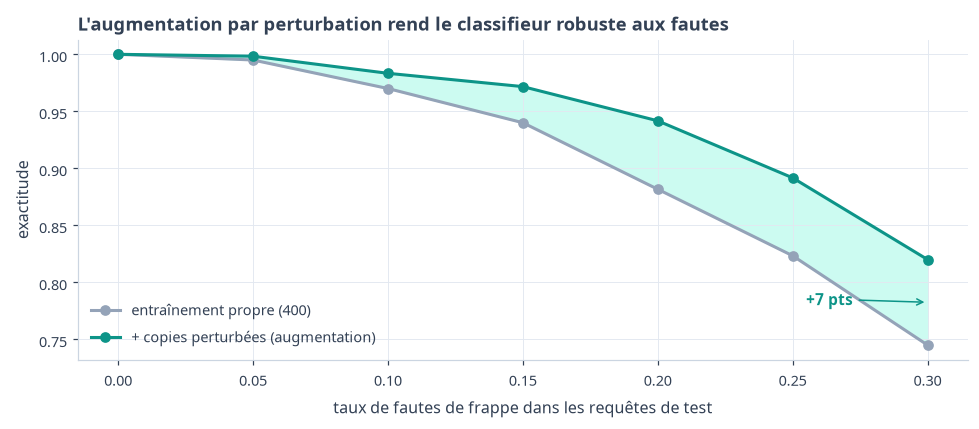

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

INTENTS = {
    "mot de passe": ["Comment {verbe} mon mot de passe ?", "J'ai {perdu} mon mot de passe {fin}",
                     "Je n'arrive plus à me connecter à mon compte {fin}", "Mot de passe {perdu}, que faire ?",
                     "Où puis-je {verbe} mon mot de passe ?"],
    "livraison": ["Où en est ma commande {fin}", "Mon colis n'est toujours pas arrivé {fin}",
                  "Quand vais-je recevoir ma livraison ?", "Comment suivre mon colis ?",
                  "Le livreur n'est pas passé {fin}"],
    "remboursement": ["Je voudrais être remboursé {fin}", "Comment obtenir un remboursement ?",
                      "Puis-je retourner un article et récupérer mon argent ?",
                      "Le produit est défectueux, je veux un remboursement {fin}", "Quel est le délai de remboursement ?"],
    "horaires": ["Quels sont vos horaires d'ouverture ?", "Le magasin est-il ouvert {jour} ?",
                 "À quelle heure fermez-vous {jour} ?", "Êtes-vous ouverts {jour} matin ?",
                 "Jusqu'à quelle heure puis-je venir {jour} ?"],
}
CHAMPS = {"verbe": ["changer", "réinitialiser", "modifier", "récupérer"], "perdu": ["oublié", "perdu", "égaré"],
          "fin": ["", ".", "!", "depuis hier", "s'il vous plaît", "merci"],
          "jour": ["dimanche", "lundi", "samedi", "le jour férié", "ce soir"]}
NOMS = list(INTENTS)


def requetes(n, seed):
    r = np.random.default_rng(seed)
    X, Y = [], []
    for _ in range(n):
        k = int(r.integers(4))
        X.append(d8.fill_template(INTENTS[NOMS[k]][r.integers(5)], CHAMPS, r).replace(" .", ".").replace(" !", "!"))
        Y.append(k)
    return X, np.array(Y)


Xtr, ytr = requetes(400, 0)
Xte, yte = requetes(600, 1)
taux = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
courbes = {}
for aug in (False, True):
    Xa = Xtr + [d8.typo_noise(x, 0.08, seed=i) for i, x in enumerate(Xtr)] if aug else Xtr
    ya = np.concatenate([ytr, ytr]) if aug else ytr
    clf = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000)).fit(Xa, ya)
    courbes[aug] = [clf.score([d8.typo_noise(x, r, seed=1000 + i) for i, x in enumerate(Xte)], yte) for r in taux]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(taux, courbes[False], "o-", color=GRAY, label="entraînement propre (400)")
ax.plot(taux, courbes[True], "o-", color=TEAL, label="+ copies perturbées (augmentation)")
ax.fill_between(taux, courbes[False], courbes[True], color=LIGHT[TEAL])
ax.annotate(f"+{(courbes[True][-1] - courbes[False][-1]) * 100:.0f} pts", xy=(0.3, (courbes[True][-1] + courbes[False][-1]) / 2),
            xytext=(0.255, 0.78), fontsize=10, color=TEAL, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=TEAL))
ax.set_xlabel("taux de fautes de frappe dans les requêtes de test")
ax.set_ylabel("exactitude")
ax.set_title("L'augmentation par perturbation rend le classifieur robuste aux fautes")
ax.legend(loc="lower left")
finish(fig)
plt.show()

Sans augmentation, chaque faute crée un mot **inconnu** du vocabulaire TF-IDF et
l'exactitude chute quand les fautes se multiplient. Les copies perturbées apprennent au
modèle que les variantes fautives existent : la chute est nettement amortie. C'est le
principe des jeux de test comme ImageNet-C (15 corruptions visuelles) cités par le livre,
appliqué ici au texte. (Une représentation par $n$-grammes de **caractères** serait,
elle, robuste par construction : l'augmentation et le choix de représentation sont deux
leviers complémentaires.)

> **À retenir.** Substitutions, contrefactuels et perturbations créent des variantes
> d'exemples réels à coût quasi nul. Elles améliorent la robustesse et atténuent des
> biais, à condition que la transformation **préserve l'étiquette** (une faute de frappe
> ne change pas l'intention ; un mauvais accord de genre, si).